# 🚗 CarDekho Used Car Price Analysis

## Project Overview
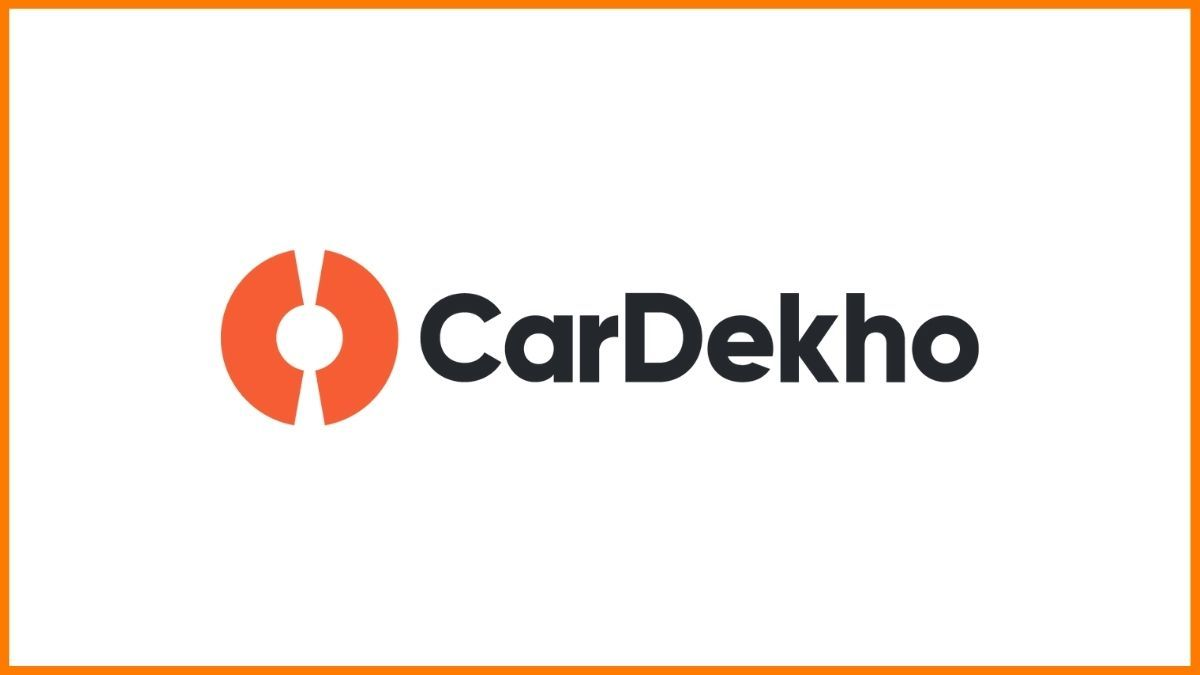

This project analyzes used car data from CarDekho to understand the factors that influence used car selling prices.

The analysis focuses on vehicle characteristics such as brand, model, fuel type, transmission, vehicle age, kilometers driven, mileage, engine size, max power, and number of seats.

Using Python, Pandas, Matplotlib, and Seaborn, the project performs data cleaning, exploratory data analysis (EDA), statistical analysis, and data visualization to identify important patterns and relationships in the dataset.

### Objectives

- Analyze the distribution of used cars by different categories.
- Understand the relationship between vehicle features and selling price.
- Identify brands and models with different pricing patterns.
- Study how vehicle age and usage relate to selling price.
- Find important correlations between car features and price.
- Generate meaningful insights from the dataset.

### Tools & Technologies

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook / Kaggle

### Dataset

**Records:** 15,244 cars after removing duplicate rows  
**Features:** 13 after data cleaning




In [115]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [116]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/paragchintanwar/cardekho/cardekho_dataset.csv


In [117]:
df = pd.read_csv('/kaggle/input/datasets/paragchintanwar/cardekho/cardekho_dataset.csv')

print(df.shape)
df.head()

(15411, 14)


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [118]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='object')

# CarDekho Datacard

| Column              | Description                      | Data Type |
| ------------------- | -------------------------------- | --------- |
| `car_name`          | Name of the car                  | Object    |
| `brand`             | Car brand/manufacturer           | Object    |
| `model`             | Car model                        | Object    |
| `vehicle_age`       | Age of the vehicle               | Integer   |
| `km_driven`         | Kilometers driven                | Integer   |
| `seller_type`       | Type of seller                   | Object    |
| `fuel_type`         | Fuel used by the car             | Object    |
| `transmission_type` | Manual or automatic transmission | Object    |
| `mileage`           | Vehicle mileage                  | Float     |
| `engine`            | Engine capacity                  | Integer   |
| `max_power`         | Maximum engine power             | Float     |
| `seats`             | Number of seats                  | Integer   |
| `selling_price`     | Selling price of the car         | Integer   |


In [119]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [120]:
df.isnull().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [121]:
df['Unnamed: 0'].head()
df['Unnamed: 0'].nunique()

15411

In [122]:
df.shape

(15411, 14)

In [123]:
# Remove unnecessary index column if it exists
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

print(df.shape)

(15411, 13)


In [124]:
print(df.columns.tolist())

['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']


In [125]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (15411, 13)
Missing Values: 0
Duplicate Rows: 167


In [126]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 167


In [127]:
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (15244, 13)
Duplicate Rows: 0


In [128]:
df.describe()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15244.000000,1.524400e+04,15244.000000,15244.000000,15244.000000,15244.000000,1.524400e+04
mean,6.041131,5.563958e+04,19.697333,1486.171543,100.607652,5.326161,7.747014e+05
std,3.016228,5.176630e+04,4.169307,520.419390,42.915687,0.808760,8.946761e+05
min,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.590000e+05
75%,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


In [129]:
df.nunique()

car_name              121
brand                  32
model                 120
vehicle_age            24
km_driven            3688
seller_type             3
fuel_type               5
transmission_type       2
mileage               411
engine                110
max_power             342
seats                   8
selling_price        1086
dtype: int64

In [130]:
df['fuel_type'].value_counts()

fuel_type
Petrol      7555
Diesel      7342
CNG          299
LPG           44
Electric       4
Name: count, dtype: int64

In [131]:
df.groupby('fuel_type')['selling_price'].mean().sort_values(ascending=False)

fuel_type
Electric    1.853500e+06
Diesel      1.000458e+06
Petrol      5.721783e+05
CNG         4.176890e+05
LPG         2.062727e+05
Name: selling_price, dtype: float64

In [132]:
fuel_price = df.groupby('fuel_type', as_index=False)['selling_price'].mean()

fuel_price

,fuel_type,selling_price
0,CNG,4.176890e+05
1,Diesel,1.000458e+06
2,Electric,1.853500e+06
3,LPG,2.062727e+05
4,Petrol,5.721783e+05


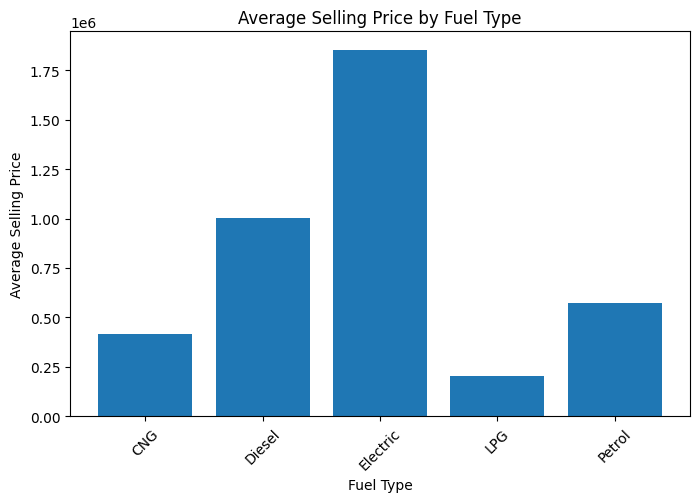

In [133]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(fuel_price['fuel_type'], fuel_price['selling_price'])
plt.xlabel('Fuel Type')
plt.ylabel('Average Selling Price')
plt.title('Average Selling Price by Fuel Type')
plt.xticks(rotation=45)
plt.show()

In [134]:
df['brand'].value_counts().head(10)

brand
Maruti        4933
Hyundai       2952
Honda         1476
Mahindra       999
Toyota         789
Ford           776
Volkswagen     614
Renault        527
BMW            436
Tata           421
Name: count, dtype: int64

In [135]:
brand_price = df.groupby('brand')['selling_price'].mean().sort_values(ascending=False).head(10)

brand_price

brand
Ferrari         3.950000e+07
Rolls-Royce     2.420000e+07
Bentley         9.266667e+06
Maserati        6.100000e+06
Lexus           5.262778e+06
Porsche         5.161190e+06
Mercedes-AMG    5.100000e+06
Land Rover      3.846880e+06
Volvo           3.729700e+06
BMW             2.686674e+06
Name: selling_price, dtype: float64

In [136]:
brand_analysis = df.groupby('brand').agg(
    car_count=('brand', 'size'),
    avg_price=('selling_price', 'mean')
).sort_values('car_count', ascending=False)

brand_analysis.head(10)

,car_count,avg_price
brand,,
Maruti,4933,4.869854e+05
Hyundai,2952,5.764790e+05
Honda,1476,6.174526e+05
Mahindra,999,7.886136e+05
Toyota,789,1.371497e+06
Ford,776,6.337165e+05
Volkswagen,614,5.155195e+05
Renault,527,4.425294e+05
BMW,436,2.686674e+06


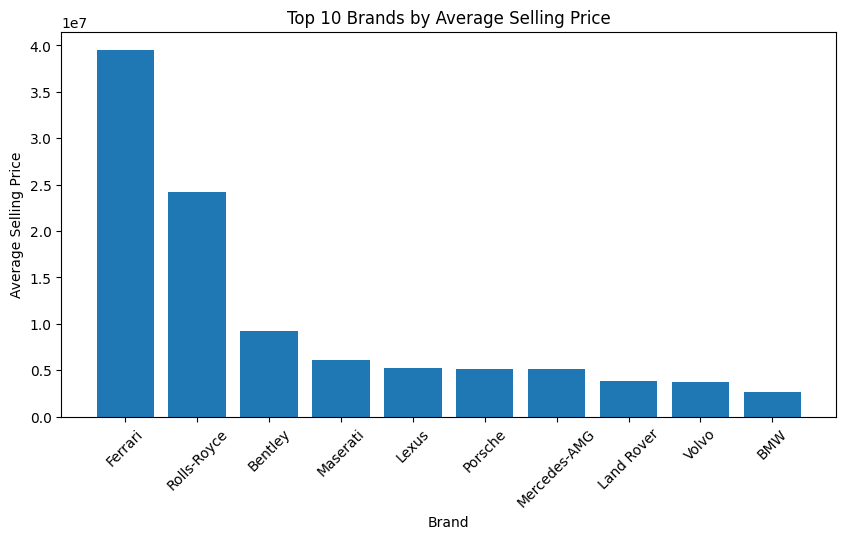

In [137]:
brand_price = brand_analysis.sort_values('avg_price', ascending=False).head(10)

plt.figure(figsize=(10,5))
plt.bar(brand_price.index, brand_price['avg_price'])
plt.xlabel('Brand')
plt.ylabel('Average Selling Price')
plt.title('Top 10 Brands by Average Selling Price')
plt.xticks(rotation=45)
plt.show()

In [138]:
age_price = df.groupby('vehicle_age', as_index=False)['selling_price'].mean()

age_price

,vehicle_age,selling_price
0,0,1.575000e+06
1,1,1.096977e+06
2,2,1.144514e+06
3,3,9.773270e+05
4,4,9.490419e+05
5,5,8.202058e+05
6,6,7.281607e+05
7,7,7.000722e+05
8,8,6.275114e+05
9,9,5.930089e+05


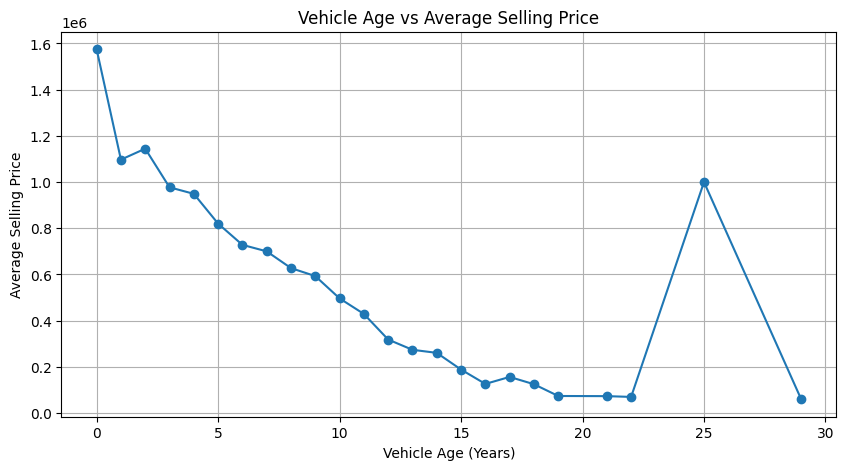

In [139]:
plt.figure(figsize=(10,5))
plt.plot(age_price['vehicle_age'], age_price['selling_price'], marker='o')
plt.xlabel('Vehicle Age (Years)')
plt.ylabel('Average Selling Price')
plt.title('Vehicle Age vs Average Selling Price')
plt.grid()
plt.show()

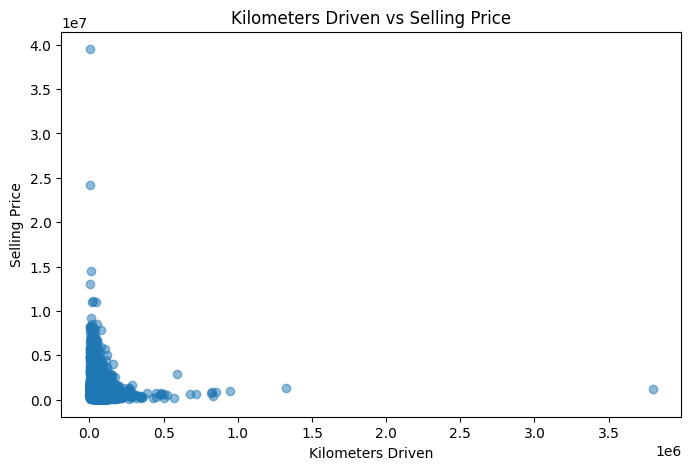

In [140]:
plt.figure(figsize=(8,5))
plt.scatter(df['km_driven'], df['selling_price'], alpha=0.5)
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price')
plt.title('Kilometers Driven vs Selling Price')
plt.show()

In [141]:
df[['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'selling_price']].corr()['selling_price'].sort_values(ascending=False)

selling_price    1.000000
max_power        0.751058
engine           0.585713
km_driven       -0.079548
vehicle_age     -0.241228
mileage         -0.305128
Name: selling_price, dtype: float64

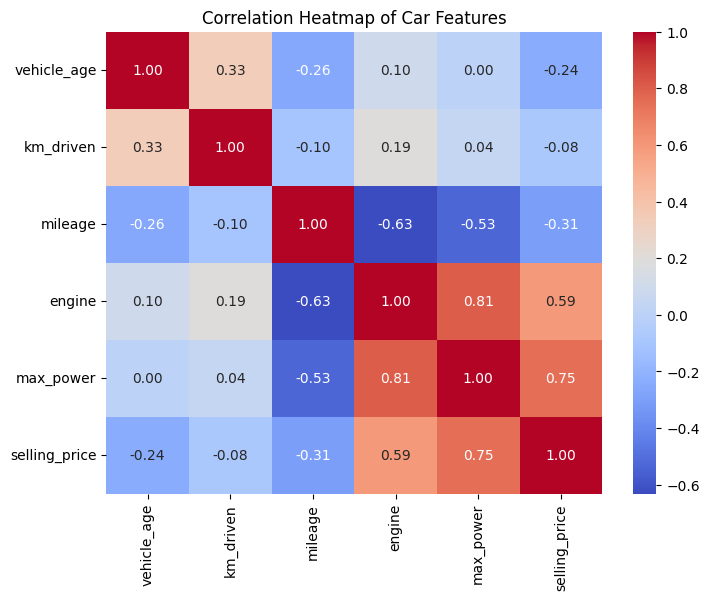

In [142]:
import seaborn as sns

corr = df[['vehicle_age', 'km_driven', 'mileage',
           'engine', 'max_power', 'selling_price']].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Car Features')
plt.show()

In [143]:
transmission_price = df.groupby(
    'transmission_type',
    as_index=False
)['selling_price'].mean()

transmission_price

,transmission_type,selling_price
0,Automatic,1.577104e+06
1,Manual,5.657079e+05


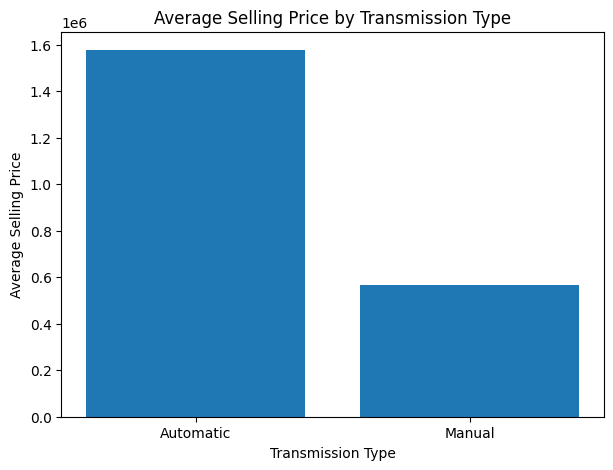

In [144]:
plt.figure(figsize=(7,5))
plt.bar(
    transmission_price['transmission_type'],
    transmission_price['selling_price']
)
plt.xlabel('Transmission Type')
plt.ylabel('Average Selling Price')
plt.title('Average Selling Price by Transmission Type')
plt.show()

In [145]:
seller_price = df.groupby(
    'seller_type',
    as_index=False
)['selling_price'].mean()

seller_price

,seller_type,selling_price
0,Dealer,870400.888043
1,Individual,619650.369743
2,Trustmark Dealer,571959.537572


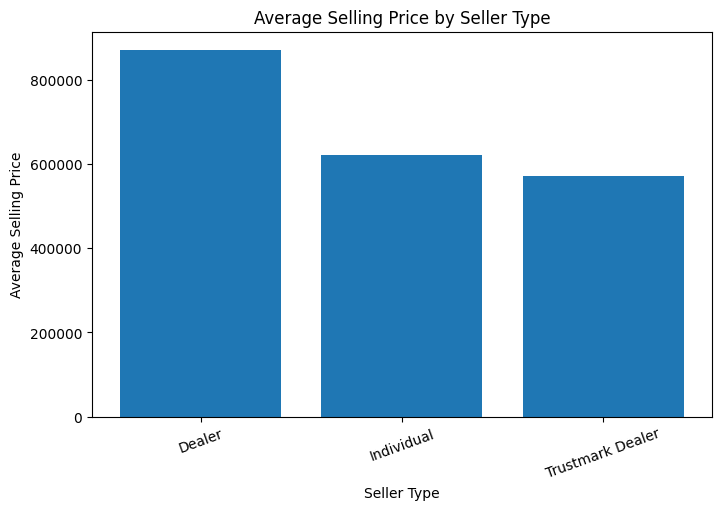

In [146]:
plt.figure(figsize=(8,5))
plt.bar(seller_price['seller_type'], seller_price['selling_price'])
plt.xlabel('Seller Type')
plt.ylabel('Average Selling Price')
plt.title('Average Selling Price by Seller Type')
plt.xticks(rotation=20)
plt.show()

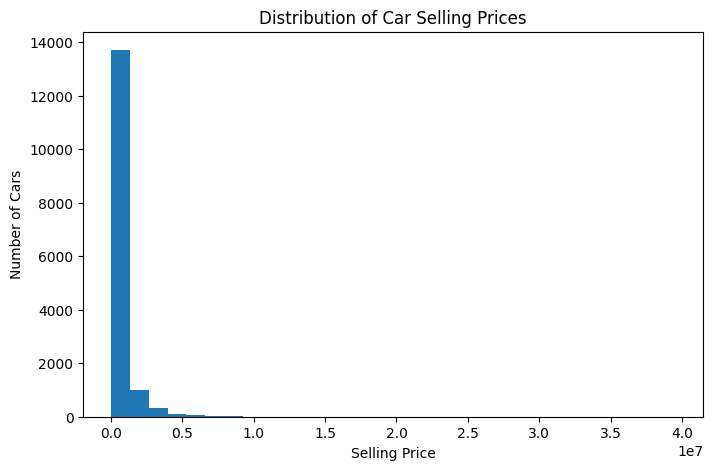

In [147]:
plt.figure(figsize=(8,5))
plt.hist(df['selling_price'], bins=30)
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.title('Distribution of Car Selling Prices')
plt.show()

In [148]:
model_price = df.groupby('model')['selling_price'].mean().sort_values(ascending=False).head(10)

model_price

model
GTC4Lusso       3.950000e+07
Ghost           2.420000e+07
Continental     9.266667e+06
RX              7.100000e+06
GLS             6.781083e+06
Ghibli          6.200000e+06
Quattroporte    6.000000e+06
Macan           5.985000e+06
X4              5.570000e+06
NX              5.450000e+06
Name: selling_price, dtype: float64

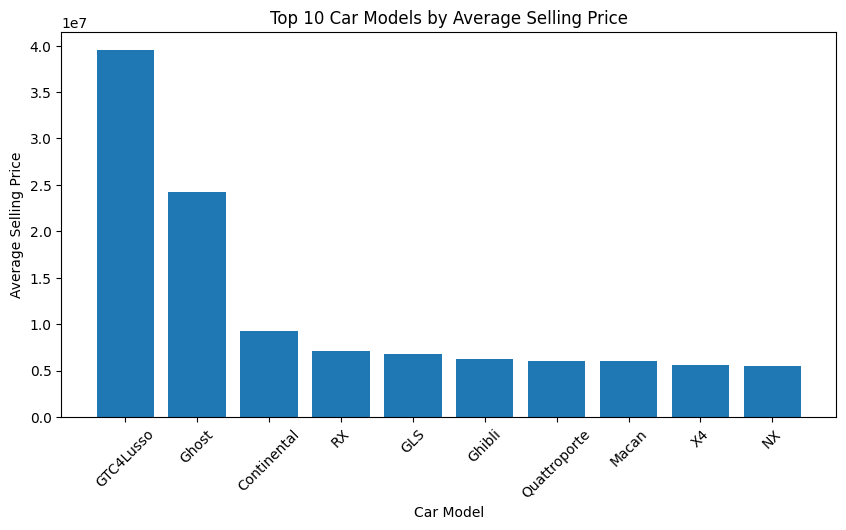

In [149]:
plt.figure(figsize=(10,5))
plt.bar(model_price.index, model_price.values)
plt.xlabel('Car Model')
plt.ylabel('Average Selling Price')
plt.title('Top 10 Car Models by Average Selling Price')
plt.xticks(rotation=45)
plt.show()

In [150]:
model_count = df['model'].value_counts().head(10)

model_count

model
i20            898
Swift Dzire    875
Swift          774
Alto           768
City           750
Wagon R        709
Grand          569
Innova         544
Verna          488
i10            406
Name: count, dtype: int64

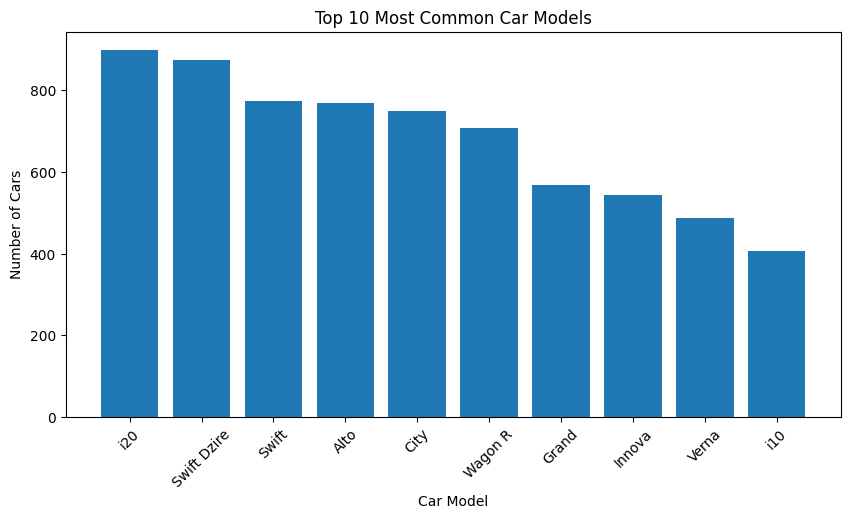

In [151]:
plt.figure(figsize=(10,5))
plt.bar(model_count.index, model_count.values)
plt.xlabel('Car Model')
plt.ylabel('Number of Cars')
plt.title('Top 10 Most Common Car Models')
plt.xticks(rotation=45)
plt.show()

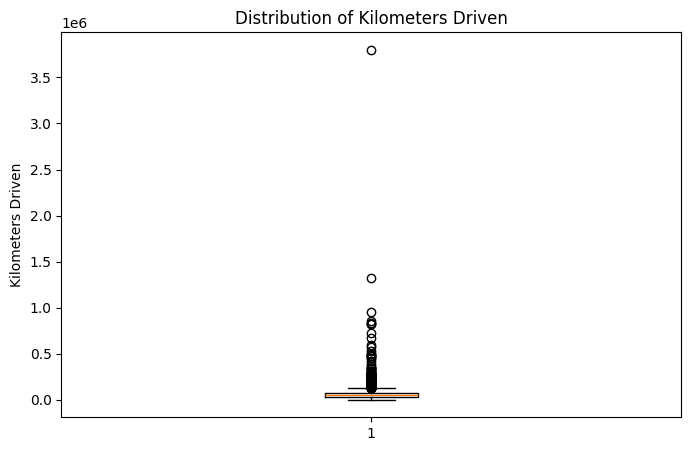

In [152]:
plt.figure(figsize=(8,5))
plt.boxplot(df['km_driven'])
plt.ylabel('Kilometers Driven')
plt.title('Distribution of Kilometers Driven')
plt.show()

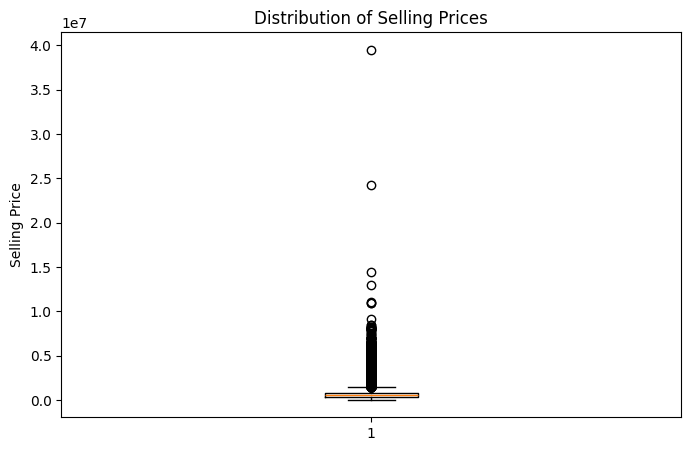

In [153]:
plt.figure(figsize=(8,5))
plt.boxplot(df['selling_price'])
plt.ylabel('Selling Price')
plt.title('Distribution of Selling Prices')
plt.show()

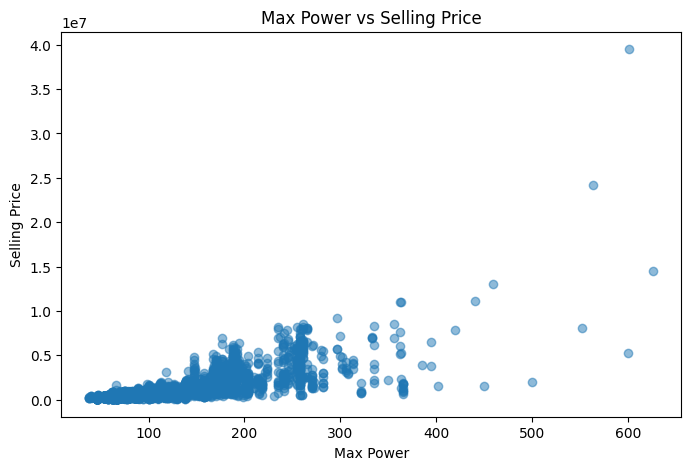

In [154]:
plt.figure(figsize=(8,5))
plt.scatter(df['max_power'], df['selling_price'], alpha=0.5)
plt.xlabel('Max Power')
plt.ylabel('Selling Price')
plt.title('Max Power vs Selling Price')
plt.show()

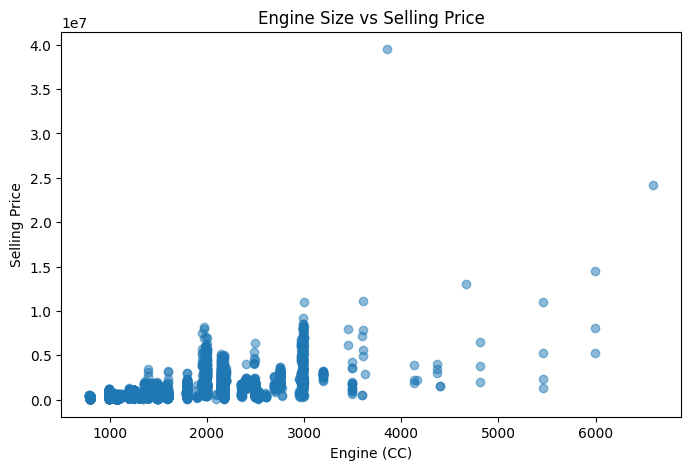

In [155]:
plt.figure(figsize=(8,5))
plt.scatter(df['engine'], df['selling_price'], alpha=0.5)
plt.xlabel('Engine (CC)')
plt.ylabel('Selling Price')
plt.title('Engine Size vs Selling Price')
plt.show()

In [156]:
correlation = df[
    ['vehicle_age', 'km_driven', 'mileage',
     'engine', 'max_power', 'selling_price']
].corr()['selling_price'].drop('selling_price')

correlation.sort_values(ascending=False)

max_power      0.751058
engine         0.585713
km_driven     -0.079548
vehicle_age   -0.241228
mileage       -0.305128
Name: selling_price, dtype: float64

In [157]:
age_price = df.groupby(
    'vehicle_age',
    as_index=False
)['selling_price'].mean()

age_price

,vehicle_age,selling_price
0,0,1.575000e+06
1,1,1.096977e+06
2,2,1.144514e+06
3,3,9.773270e+05
4,4,9.490419e+05
5,5,8.202058e+05
6,6,7.281607e+05
7,7,7.000722e+05
8,8,6.275114e+05
9,9,5.930089e+05


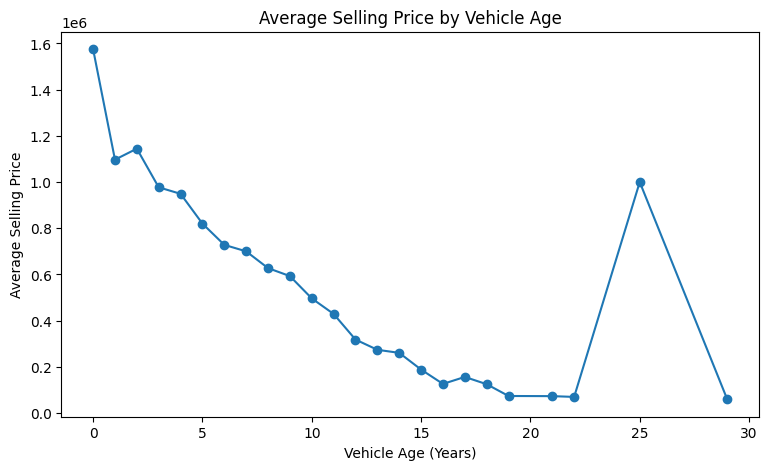

In [158]:
plt.figure(figsize=(9,5))

plt.plot(age_price['vehicle_age'], age_price['selling_price'], marker='o')

plt.xlabel('Vehicle Age (Years)')
plt.ylabel('Average Selling Price')
plt.title('Average Selling Price by Vehicle Age')

plt.show()

In [159]:
brand_count = df['brand'].value_counts().head(10)

brand_count

brand
Maruti        4933
Hyundai       2952
Honda         1476
Mahindra       999
Toyota         789
Ford           776
Volkswagen     614
Renault        527
BMW            436
Tata           421
Name: count, dtype: int64

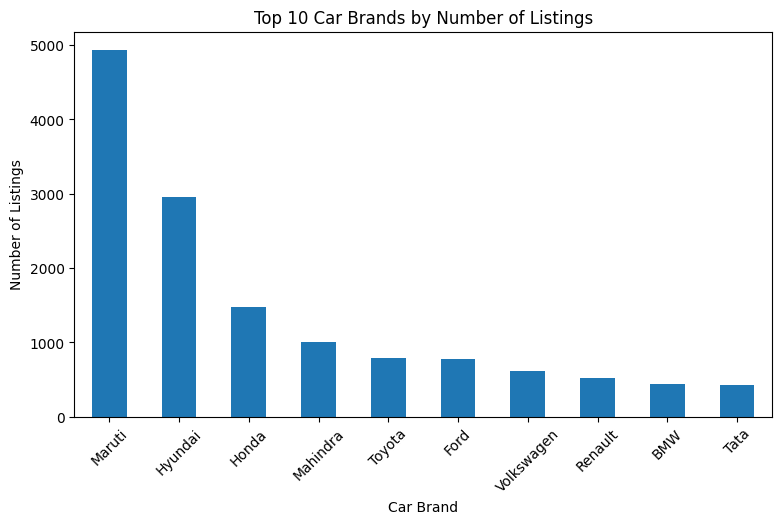

In [160]:
plt.figure(figsize=(9,5))

brand_count.plot(kind='bar')

plt.xlabel('Car Brand')
plt.ylabel('Number of Listings')
plt.title('Top 10 Car Brands by Number of Listings')

plt.xticks(rotation=45)
plt.show()

In [161]:
print("KEY INSIGHTS")
print("-" * 40)

print("1. Max power has the strongest positive relationship with selling price.")
print("2. Engine size also has a positive relationship with selling price.")
print("3. Older vehicles generally have lower selling prices.")
print("4. Higher mileage is associated with lower selling prices.")
print("5. Kilometers driven has a weak relationship with selling price.")
print("6. Diesel and automatic cars have higher average selling prices in this dataset.")
print("7. Maruti and Hyundai are the most common brands in the dataset.")

KEY INSIGHTS
----------------------------------------
1. Max power has the strongest positive relationship with selling price.
2. Engine size also has a positive relationship with selling price.
3. Older vehicles generally have lower selling prices.
4. Higher mileage is associated with lower selling prices.
5. Kilometers driven has a weak relationship with selling price.
6. Diesel and automatic cars have higher average selling prices in this dataset.
7. Maruti and Hyundai are the most common brands in the dataset.


In [162]:
print("PROJECT SUMMARY")
print("-" * 40)

print(f"Total Cars Analyzed: {len(df):,}")
print(f"Average Selling Price: ₹{df['selling_price'].mean():,.0f}")
print(f"Median Selling Price: ₹{df['selling_price'].median():,.0f}")
print(f"Average Vehicle Age: {df['vehicle_age'].mean():.1f} years")
print(f"Average Kilometers Driven: {df['km_driven'].mean():,.0f}")
print(f"Most Common Brand: {df['brand'].mode()[0]}")
print(f"Most Common Fuel Type: {df['fuel_type'].mode()[0]}")
print(f"Most Common Transmission: {df['transmission_type'].mode()[0]}")

PROJECT SUMMARY
----------------------------------------
Total Cars Analyzed: 15,244
Average Selling Price: ₹774,701
Median Selling Price: ₹559,000
Average Vehicle Age: 6.0 years
Average Kilometers Driven: 55,640
Most Common Brand: Maruti
Most Common Fuel Type: Petrol
Most Common Transmission: Manual


In [163]:
price_bins = [0, 300000, 600000, 1000000, 2000000, 5000000, float('inf')]
price_labels = ['Below 3L', '3L-6L', '6L-10L', '10L-20L', '20L-50L', 'Above 50L']

df['price_range'] = pd.cut(
    df['selling_price'],
    bins=price_bins,
    labels=price_labels
)

price_range_count = df['price_range'].value_counts().sort_index()
price_range_count

price_range
Below 3L     2259
3L-6L        6282
6L-10L       4222
10L-20L      1704
20L-50L       662
Above 50L     115
Name: count, dtype: int64

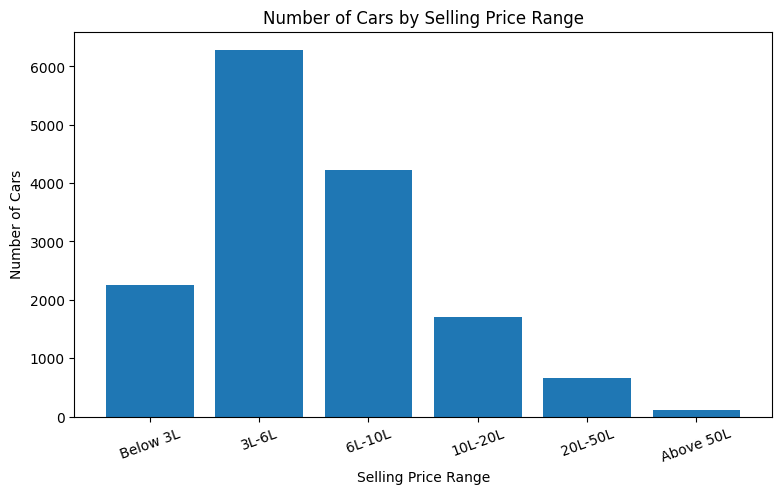

In [164]:
plt.figure(figsize=(9,5))

plt.bar(price_range_count.index, price_range_count.values)

plt.xlabel('Selling Price Range')
plt.ylabel('Number of Cars')
plt.title('Number of Cars by Selling Price Range')

plt.xticks(rotation=20)
plt.show()

In [165]:
print("PROJECT SUMMARY")
print("-" * 40)

print(f"Total Cars Analyzed: {len(df):,}")
print(f"Average Selling Price: ₹{df['selling_price'].mean():,.0f}")
print(f"Median Selling Price: ₹{df['selling_price'].median():,.0f}")
print(f"Average Vehicle Age: {df['vehicle_age'].mean():.1f} years")
print(f"Average Kilometers Driven: {df['km_driven'].mean():,.0f}")
print(f"Most Common Brand: {df['brand'].mode()[0]}")
print(f"Most Common Fuel Type: {df['fuel_type'].mode()[0]}")
print(f"Most Common Transmission: {df['transmission_type'].mode()[0]}")

PROJECT SUMMARY
----------------------------------------
Total Cars Analyzed: 15,244
Average Selling Price: ₹774,701
Median Selling Price: ₹559,000
Average Vehicle Age: 6.0 years
Average Kilometers Driven: 55,640
Most Common Brand: Maruti
Most Common Fuel Type: Petrol
Most Common Transmission: Manual


In [166]:
print("FINAL DATA QUALITY CHECK")
print("-" * 40)

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

FINAL DATA QUALITY CHECK
----------------------------------------
Dataset Shape: (15244, 14)

Missing Values:
0

Duplicate Rows: 0


## 🔍 Key Insights

- **Max Power:** Shows the strongest positive relationship with selling price (correlation ≈ 0.75).
- **Engine Size:** Shows a moderate positive relationship with selling price (correlation ≈ 0.59).
- **Vehicle Age:** Older vehicles generally show lower selling prices.
- **Mileage:** Shows a negative relationship with selling price.
- **Kilometers Driven:** Shows only a weak negative relationship with selling price.
- **Fuel Type:** Petrol and Diesel vehicles dominate the dataset.
- **Transmission:** Automatic vehicles have a higher average selling price than manual vehicles.
- **Brands:** Maruti and Hyundai are among the most frequently listed brands.
- **Price Range:** Most vehicles are concentrated in the ₹3–10 lakh selling price range.

## 📌 Conclusion

The analysis shows that vehicle specifications such as max power and engine size have strong positive relationships with used car selling prices. Vehicle age and mileage generally show negative relationships with price.

The dataset is mainly dominated by Petrol and Diesel vehicles, while Maruti is the most frequently listed brand and Manual is the most common transmission type.

Overall, this project demonstrates how Python can be used for data cleaning, exploratory data analysis, statistical analysis, data visualization, and extracting meaningful insights from used car data.